# Weather image classification for rain detection

This notebook supports a rain detection use case for Rwanda: a small convolutional network (CNN), trained from scratch, sorts sky photos into four classes: **cloudy**, **rainy**, **shiny** (clear sun) and **sunrise**. The model is served by a FastAPI service with ONNX Runtime and can be retrained with uploaded images.

What this notebook does:

- It works from **saved results only**. Training ran on a Kaggle T4 GPU with `src/experiments.py`, and every run wrote its history, validation predictions and metrics to `experiments/`. The notebook reads those files and does not retrain.
- It **does not evaluate the test set**. The test set was locked for the whole project and was evaluated exactly once, inside the Section 7 final-model job (`src/final_model.py`). The test cells at the end only read the record of that single evaluation: `models/metrics.json`, or `experiments/final_model/metrics.json` when the served record has no test section.
- Every table and figure comes from a small function in `src/` (mostly `src/notebook_views.py`), so the notebook shows results without copying logic.

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config, grids, selection
from src import notebook_views as views
from src.preprocessing import add_batch_dimension

%matplotlib inline
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
results = views.load_results()
print(f"{len(results)} experiment runs from sections {sorted(int(n) for n in results['section'].unique())}, "
      f"{len(views.load_all_results()) - len(results)} final-model runs (section 7) kept apart")

59 experiment runs from sections [3, 5], 5 final-model runs (section 7) kept apart


## 1. Data acquisition

- Source: the Roboflow "weather classification" dataset, folder-structure export (one folder per class inside `train/`, `valid/` and `test/`).
- The original export has 1099 JPG images. Section 1 found exact and near-duplicate copies with a perceptual hash (dHash) plus a pixel check, and moved 102 copies to `data/quarantine/` (`experiments/audit/DUPLICATE_REPORT.md`). Duplicates across splits would leak training images into validation or test and inflate the scores.
- The table below is the file count per class and split after the cleanup, read from the Section 1 audit. The test images themselves are not opened here.

In [2]:
counts = views.split_counts()
counts

,cloudy,rainy,shiny,sunrise,total
split,,,,,
train,182,142,145,250,719
valid,48,20,33,43,144
test,29,29,40,36,134
total,259,191,218,329,997


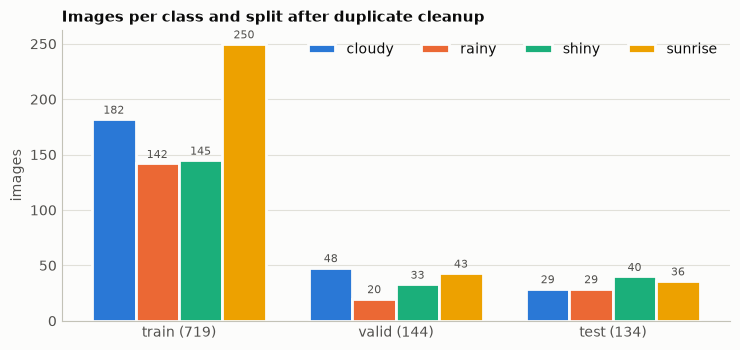

In [3]:
views.plot_split_counts(counts)

**Reading the counts**

- Sunrise is the largest class in train (250) and rainy the smallest (142). The imbalance is moderate, so class weights were tried as one of the techniques.
- Validation has only **20 rainy images** and test has 29. One extra mistake on rainy moves the rainy F1 by several points, which is why every configuration was run with several seeds and reported as a mean and a standard deviation (std).

A random sample of training and validation images per class (Section 2):

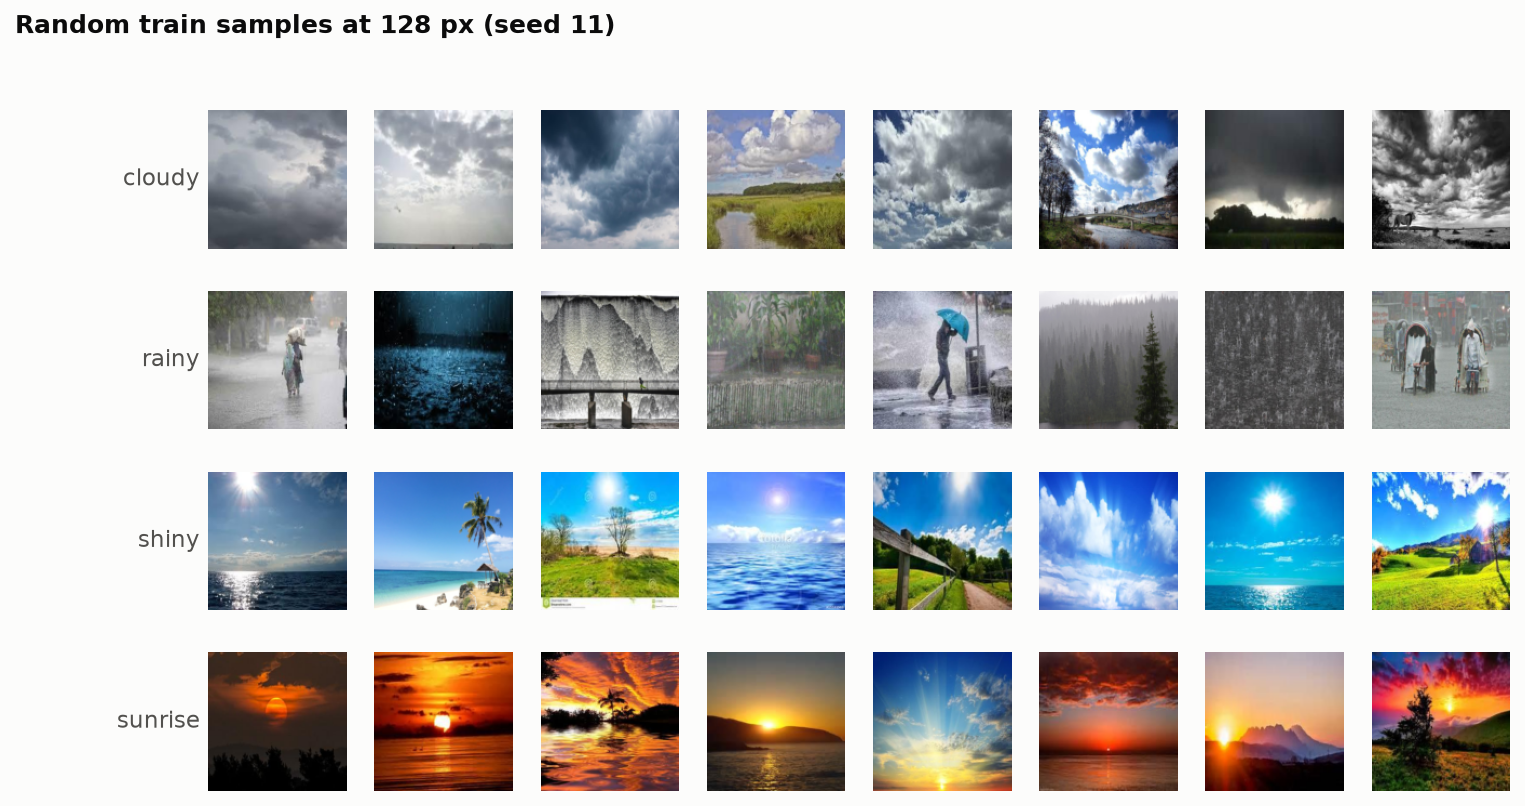

In [4]:
Image(filename=str(config.FIGURES_DIR / "sample_grid.png"))

Most images are small web photos of about 300 x 168 pixels, and a few are 1920 x 1080. Section 2 compared 96, 128 and 160 pixels and kept **128 x 128** as the model input: it keeps the texture that separates rainy from cloudy while staying cheap to train and serve.

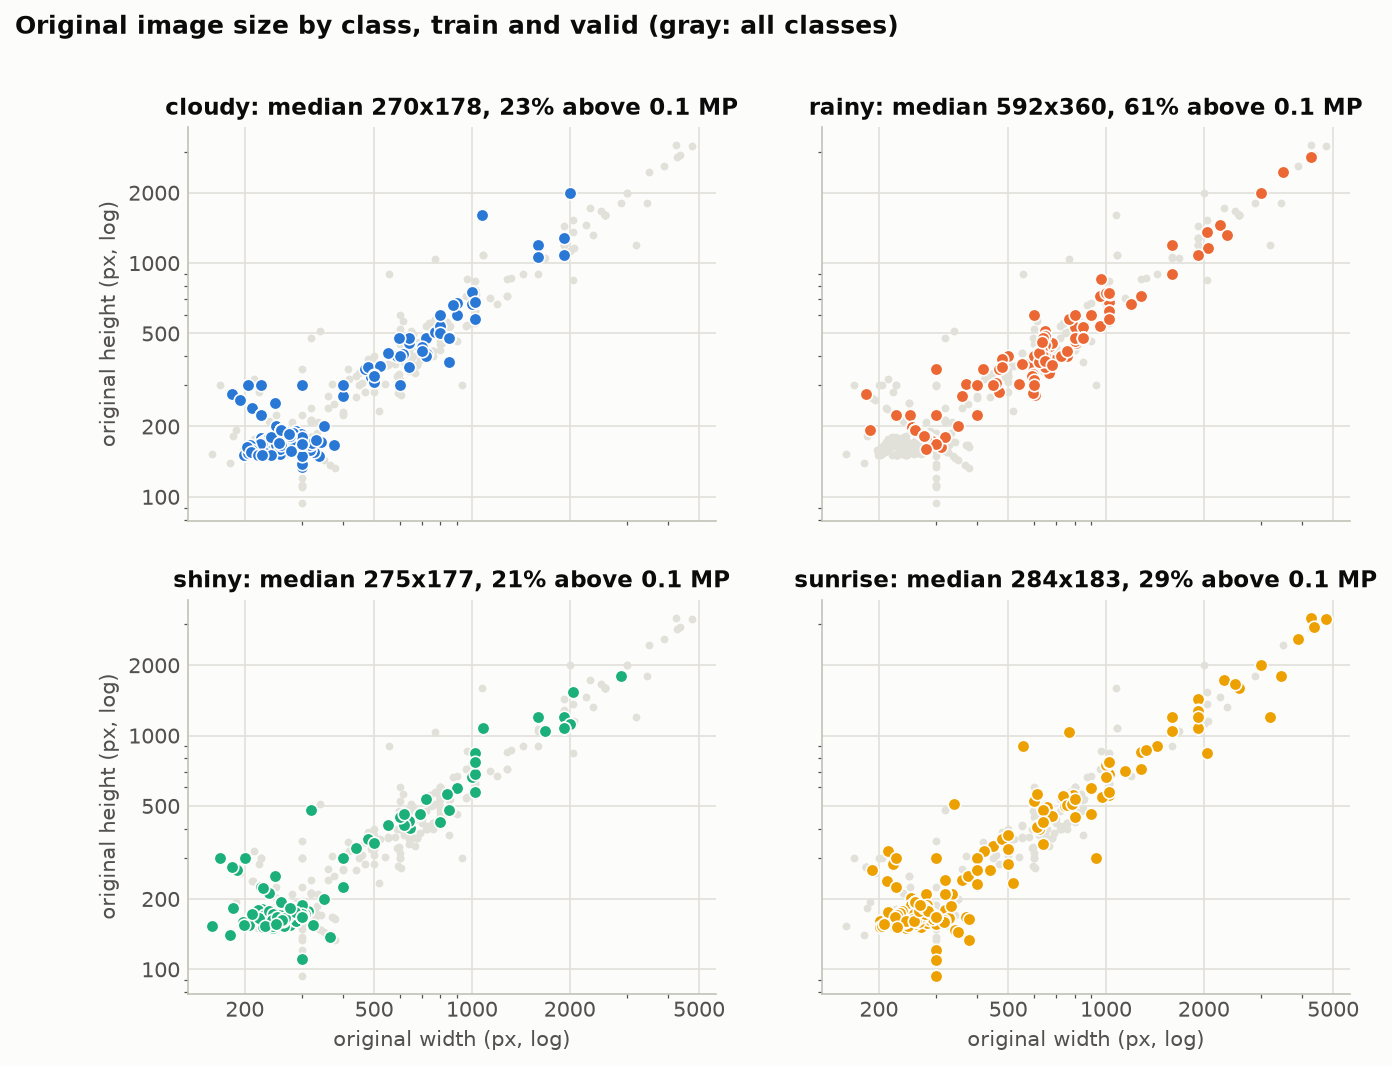

In [5]:
Image(filename=str(config.FIGURES_DIR / "image_size_distribution.png"))

## 2. Preprocessing

The same functions in `src/preprocessing.py` are used for training, for the API and for retraining, so a photo is prepared the same way everywhere. Below, each step is applied to one real training image, with the shape, type and value range after the step.

In [6]:
path = views.example_image("train", "rainy", 0)
steps, images = views.preprocessing_steps(path)
print(Path(path).name)
steps

rain100_jpg.rf.8d1735f096bb80ba515514d5480eaee2.jpg


,function,shape,dtype,min,max
step,,,,,
1 decode the file,open_image_bytes,2059 x 1158 (width x height),PIL mode RGB,NaN,NaN
"2 fix orientation, force RGB",to_rgb,2059 x 1158 (width x height),PIL mode RGB,NaN,NaN
3 resize,resize_image(size=128),128 x 128 (width x height),PIL mode RGB,NaN,NaN
4 to an array,to_array,"(128, 128, 3)",uint8,3.000000,254.000000
5 scale to 0..1,normalize_array,"(128, 128, 3)",float32,0.011765,0.996078


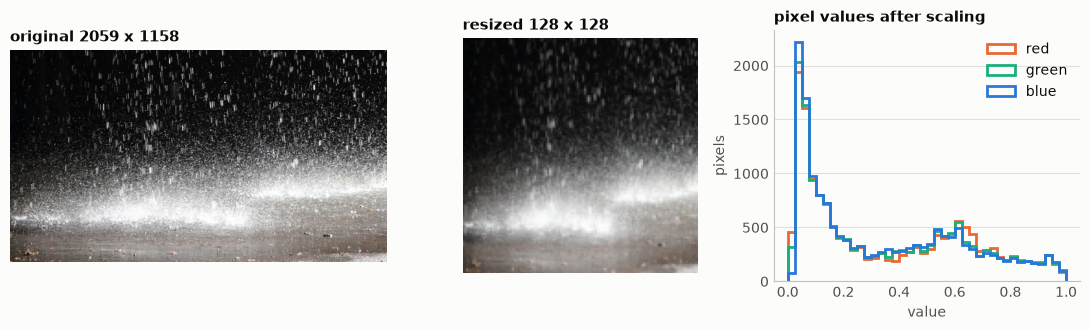

In [7]:
views.plot_preprocessing(images)

**What each step does**

1. `open_image_bytes` decodes the JPG bytes (the API receives bytes, so files are read the same way).
2. `to_rgb` applies the EXIF rotation, puts transparent images on white, and converts every image to 3-channel RGB, so grayscale or PNG uploads do not break the model.
3. `resize_image` resizes to 128 x 128 with bilinear filtering. The aspect ratio is not kept, the network sees the whole sky in every image.
4. `to_array` turns the image into a `uint8` array of shape (128, 128, 3), values 0 to 255.
5. `normalize_array` divides by 255, giving `float32` values between 0 and 1.

For a single prediction, the API adds a batch dimension:

In [8]:
add_batch_dimension(images["normalized"]).shape

(1, 128, 128, 3)

**Data augmentation (training only)**

During training, each image is randomly changed every time it is seen, so the network cannot memorize exact pixels. The strengths are defined in `src/config.py`:

In [9]:
pd.DataFrame(config.AUGMENT_STRENGTHS).T

,flip,zoom,brightness,contrast,saturation,hue
none,None,None,None,None,None,None
light,True,0.05,0.05,0.1,0.1,0.0
medium,True,0.1,0.1,0.2,0.2,0.0
strong,True,0.2,0.2,0.35,0.2,0.0


- `flip` mirrors the image left to right, `zoom` crops in by up to the given share, `brightness`, `contrast` and `saturation` change the colors by up to the given amount.
- **Hue is always 0**. A hue shift turns an orange sunrise sky into a blue or green one, which would change the label (Section 2, S2-E2). Saturation is capped at 0.2 for the same reason.
- Augmentation runs inside the TensorFlow input pipeline, so the preview below was saved in Section 2 (medium strength, the strength used by the selected model):

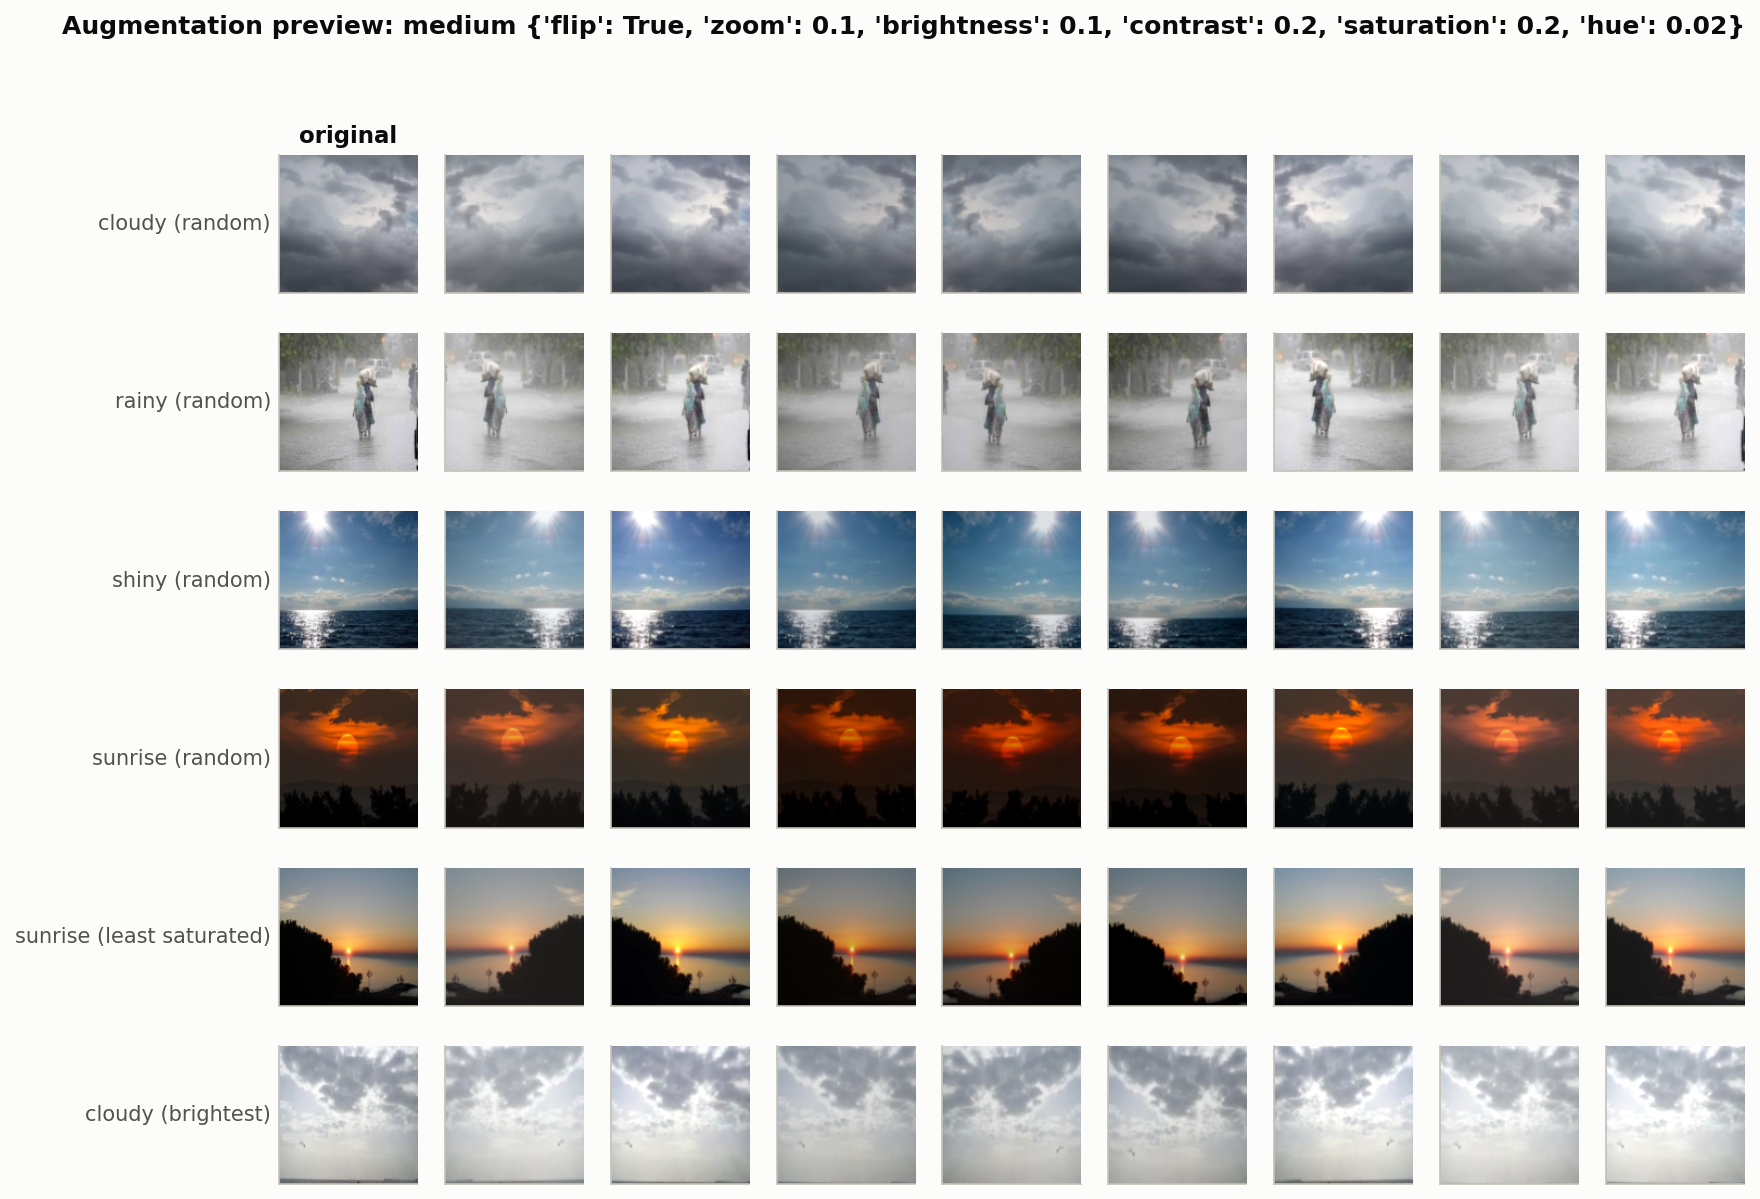

In [10]:
Image(filename=str(config.FIGURES_DIR / "augmentation_preview_medium.png"))

## 3. What separates the classes (exploratory analysis)

Simple color and texture features computed on train and valid at 128 pixels (Section 2):

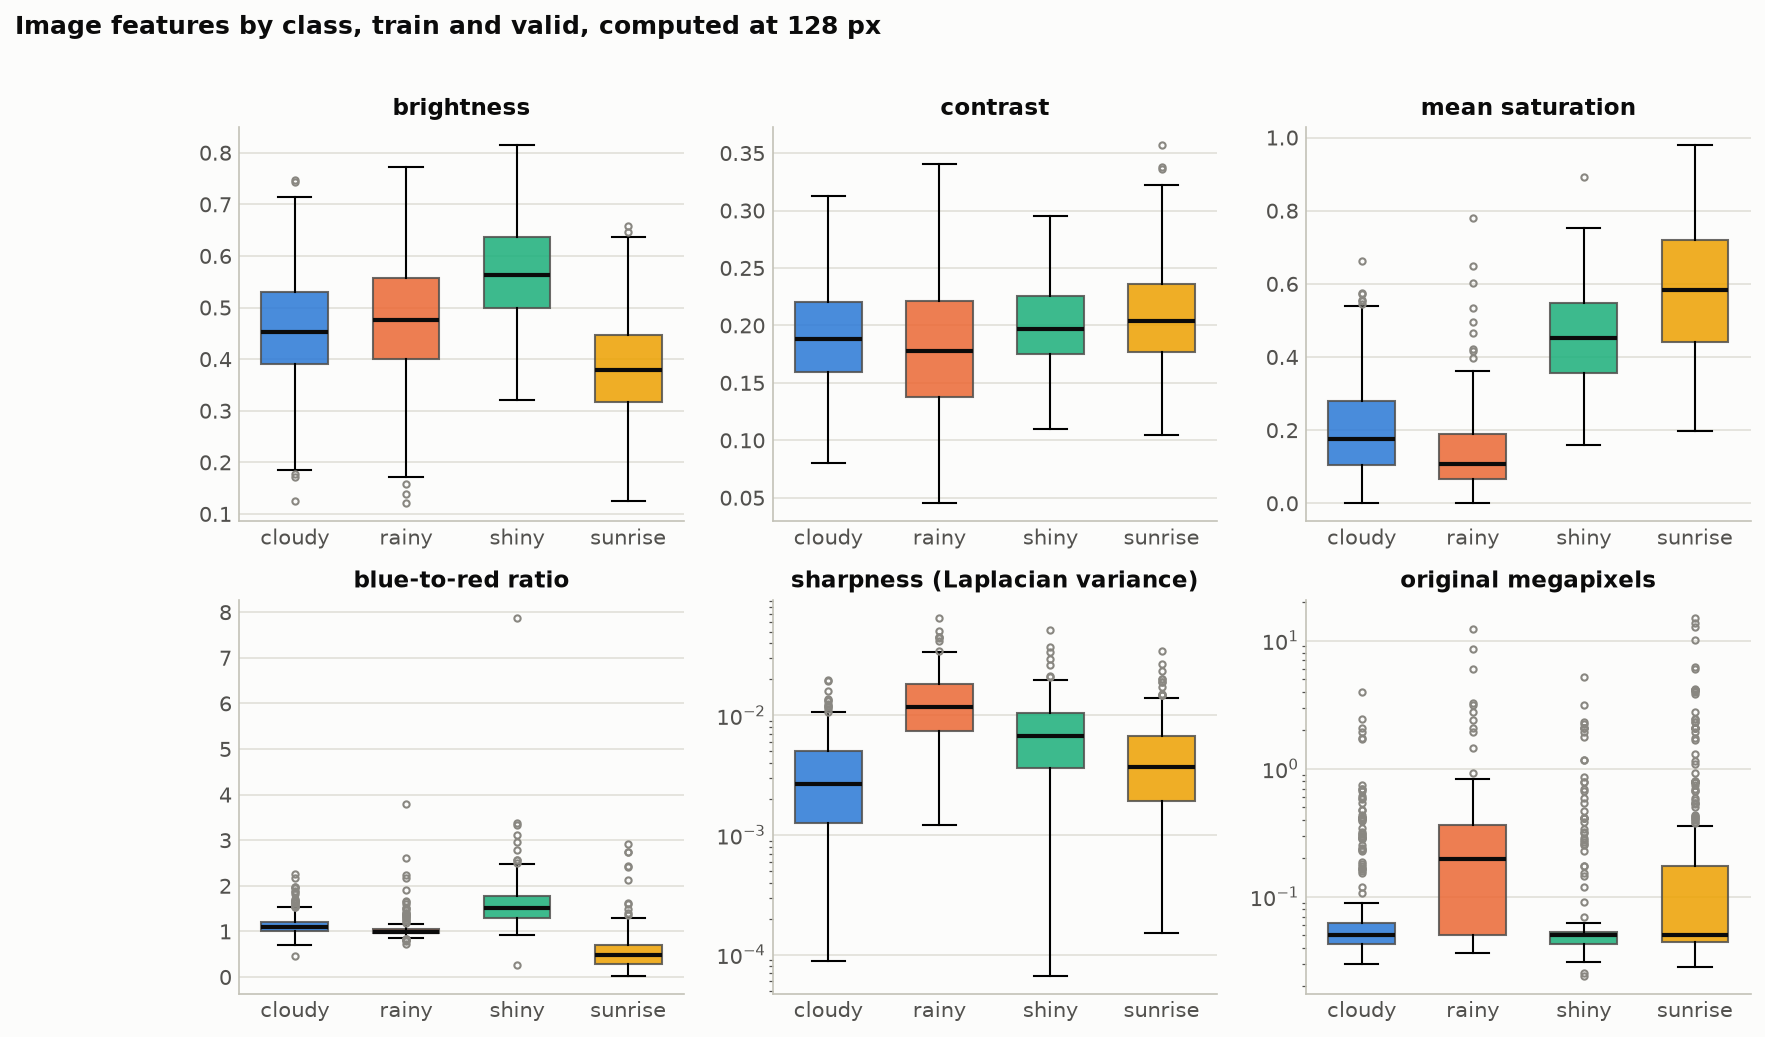

In [11]:
Image(filename=str(config.FIGURES_DIR / "feature_boxplots.png"))

- **Sunrise** is the easiest class: low blue-to-red ratio and high saturation separate it almost perfectly from shiny (AUC 0.04 on blue-to-red ratio).
- **Shiny** is the brightest class with the most green and blue.
- **Rainy against cloudy** is hard on color alone (brightness AUC 0.55, no separation). Rainy images are sharper (rain streaks, drops on glass, splashes): sharpness separates rainy from cloudy with AUC 0.90. The CNN has to learn texture, not only color.

## 4. How the experiments were run

Every number below follows the same protocol (`CLAUDE.md`, experiment rules):

- **Training to convergence**: up to 150 epochs, early stopping on validation loss (patience 15 unless stated) with the best weights restored, and `ReduceLROnPlateau` (halve the learning rate after 5 epochs without improvement).
- **Seeds**: every configuration that matters ran with 5 seeds (11, 22, 33, 44, 55). Results are the mean and std over seeds. A difference smaller than one std is treated as **no difference**.
- **One change at a time** against a named reference, with a written hypothesis before the run (`experiments/EXPERIMENT_LOG.md`).
- **Validation only**: all decisions use the 144 validation images. The test set is locked.
- Training ran on Kaggle (one T4 GPU, TensorFlow 2.21.0). `experiments/results.csv` has one row per run.

In [12]:
results.groupby("section").agg(runs=("run_id", "count"), configs=("cfg_name", "nunique"),
                               gpu_minutes=("minutes", "sum")).round(1)

,runs,configs,gpu_minutes
section,,,
3,11,3,8.2
5,48,12,49.0


## 5. Baseline and optimized model (Section 3)

Two starting points:

- **Baseline**: a plain CNN with 2 convolution layers, a flatten layer and a dense layer. No batch norm, dropout, L2, augmentation or class weights. It has 8.4 million parameters, almost all in the dense layer after the flatten.
- **R0**: the optimized design with every technique switched on: 3 blocks of 2 convolutions, batch normalization, dropout 0.3, L2 weight decay 1e-4, global average pooling instead of flatten, medium augmentation and class weights. It has 305 thousand parameters.

Both use the Adam optimizer at learning rate 1e-3, early stopping and the learning rate schedule. The selected model (Section 8 below) is R0 with a later stopping rule.

In [13]:
keys = ["blocks", "convs_per_block", "base_filters", "batch_norm", "bn_momentum", "dropout", "l2", "pooling",
        "dense_units", "optimizer", "learning_rate", "augment", "class_weights", "lr_schedule",
        "early_stop_patience", "min_epochs", "max_epochs", "image_size", "batch_size"]
named = {"baseline": grids.BASELINE, "R0": grids.R0, "selected": grids.final_config()}
pd.DataFrame({name: {**config.OPTIONAL_CONFIG_DEFAULTS, **cfg} for name, cfg in named.items()}).reindex(keys)

,baseline,R0,selected
blocks,2,3,3
convs_per_block,1,2,2
base_filters,32,32,32
batch_norm,False,True,True
bn_momentum,0.99,0.99,0.99
dropout,0.0,0.3,0.3
l2,0.0,0.0001,0.0001
pooling,flatten,gap,gap
dense_units,128,128,128
optimizer,adam,adam,adam


In [14]:
views.summary(results, ["baseline", "r0"])

,seeds,f1_mean,f1_std,f1_min,f1_max,rainy_f1_mean,rainy_f1_min,best_epoch_mean,epochs_mean,minutes_mean
cfg_name,,,,,,,,,,
baseline,5.0,0.908,0.027,0.872,0.943,0.963,0.889,7.6,22.6,0.287
r0,5.0,0.659,0.260,0.429,0.941,0.390,0.000,22.8,37.8,1.101


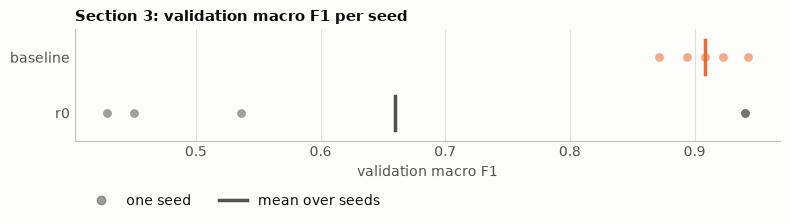

In [15]:
views.plot_seed_scores(results, ["baseline", "r0"], "Section 3: validation macro F1 per seed")

**Reading the result**

- The baseline is strong and stable: 0.908 +- 0.027 macro F1.
- R0 is **bimodal**: seeds 33 and 55 reach 0.941, better than every baseline seed but one, while seeds 11, 22 and 44 stopped after 16 epochs with their best epoch at epoch 1 and almost every rainy image called cloudy. Its mean (0.659) is useless as a model, but the two good seeds show what the design can do.

## 6. Why R0 stalled: batch normalization momentum

The two curves below compare a failed R0 seed with a successful one.

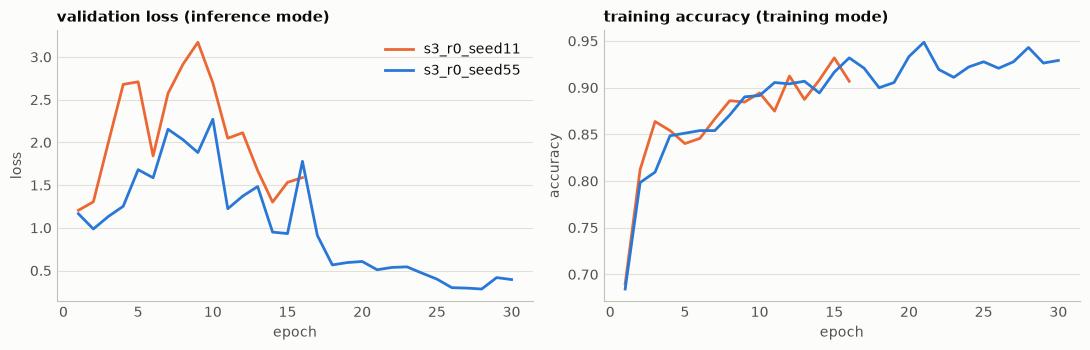

In [16]:
views.plot_stall("s3_r0_seed11", "s3_r0_seed55")

- **Training is fine in both runs**: training accuracy climbs smoothly to about 0.93.
- **Validation loss explodes** between epochs 5 and 10, then recovers. Validation runs in inference mode, where batch normalization uses its *moving* averages of the mean and variance instead of the statistics of the current batch.
- With momentum 0.99, each update keeps 99% of the old average. With only 719 training images there are 23 steps per epoch, so the averages move very slowly. The table shows how much of the initial value (mean 0, variance 1) is still inside the moving averages:

In [17]:
views.momentum_lag_table()

,after 1 epochs,after 2 epochs,after 5 epochs,after 10 epochs,after 15 epochs,after 20 epochs
momentum 0.99,79.4%,63.0%,31.5%,9.9%,3.1%,1.0%
momentum 0.9,8.9%,0.8%,0.0%,0.0%,0.0%,0.0%
momentum 0.8,0.6%,0.0%,0.0%,0.0%,0.0%,0.0%


- At momentum 0.99, 79% of the moving statistics are still the initial values after one epoch and 10% after ten epochs. In that window the network in inference mode sees badly scaled activations, so validation loss is wrong even though the weights are good.
- **Early stopping** (patience 15) then compares every epoch with epoch 1 or 2. If the recovery comes after epoch 16, training stops and the epoch 1 weights are restored. That is a race: seeds 33 and 55 recovered in time, seeds 11, 22 and 44 did not.
- At momentum 0.9 the averages forget 91% of the initial values in one epoch, so the lag disappears.

## 7. Optimization techniques tried (Section 5)

Each line changes **one thing** and is compared with its reference: R0 for the stall fixes, the baseline for the ablation (adding one R0 technique at a time to the plain CNN).

| technique | what it does |
|---|---|
| Batch norm momentum 0.9 or 0.8 | the moving averages follow the weights faster (less lag) |
| Early stopping patience 30, no stop before epoch 21 | early stopping and the best-weight restore ignore the lag phase |
| Learning rate 3e-4 | smaller optimizer steps (Adam) |
| Learning rate warmup | the learning rate rises from 2e-4 to 1e-3 over the first 5 epochs |
| Light augmentation | weaker random flips, zooms and color changes than medium |
| Batch normalization | normalizes the activations of each layer during training |
| Dropout 0.3 | randomly switches off 30% of the units during training (regularization) |
| L2 1e-4 | penalizes large weights (regularization, weight decay) |
| Class weights | gives each class the same total weight in the loss despite the imbalance |
| Medium augmentation | random changes to each training image (see Section 2) |
| Global average pooling (GAP) | averages each feature map to one number instead of flattening, which removes the 8.4 million dense weights |

The verdict uses the project rule: a difference smaller than one std (the larger of the two) is **no difference**. A **collapsed seed** is a run whose best epoch was 1 or 2 and that stopped at epoch 16 or 17, the batch norm lag failure from Section 6.

In [18]:
techniques = views.technique_table(results)
techniques

,config,seeds,macro F1 mean,std,worst seed,compared with,difference,collapsed seeds,verdict
technique,,,,,,,,,
Batch norm momentum 0.9 (instead of 0.99),r0_bn_momentum_0.9,5,0.940,0.005,0.934,r0,0.281,0,better
Batch norm momentum 0.8,r0_bn_momentum_0.8,5,0.936,0.018,0.910,r0,0.277,0,better
"Early stopping patience 30, no stop before epoch 21",r0_patience30_min20,5,0.937,0.004,0.934,r0,0.277,0,better
Learning rate 3e-4 (instead of 1e-3),r0_lr3e-4,5,0.767,0.359,0.125,r0,0.108,1,no difference (within one std)
5-epoch learning rate warmup,r0_warmup5,5,0.777,0.365,0.125,r0,0.118,1,no difference (within one std)
Light augmentation (instead of medium),r0_augment_light,5,0.481,0.278,0.233,r0,-0.178,4,no difference (within one std)
Batch norm added to the baseline,baseline_plus_batch_norm,3,0.547,0.090,0.443,baseline,-0.361,3,worse
Dropout 0.3 added to the baseline,baseline_plus_dropout,3,0.891,0.004,0.886,baseline,-0.017,0,no difference (within one std)
L2 1e-4 added to the baseline,baseline_plus_l2,3,0.894,0.011,0.882,baseline,-0.014,0,no difference (within one std)


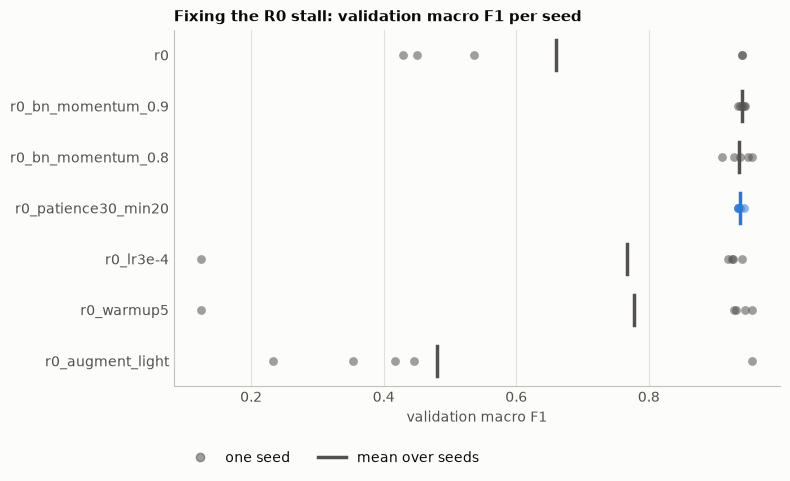

In [19]:
r0_variants = ["r0", "r0_bn_momentum_0.9", "r0_bn_momentum_0.8", "r0_patience30_min20", "r0_lr3e-4", "r0_warmup5",
               "r0_augment_light"]
views.plot_seed_scores(results, r0_variants, "Fixing the R0 stall: validation macro F1 per seed")

**Stall fixes (5 seeds each)**

- **Batch norm momentum 0.9**: every seed converges, 0.940 +- 0.005. Momentum 0.8 gives the same mean with more spread (0.936 +- 0.018).
- **Patience 30 with no stop before epoch 21** keeps momentum 0.99 but waits out the lag: every seed converges, 0.937 +- 0.004, at the cost of longer runs (73 epochs on average against 49).
- **Learning rate 3e-4** and **warmup** do not fix the stall: the lag depends on the number of steps, not on the step size. Each lost one seed (seed 22, every validation image called cloudy). Their converged seeds are as good as the others.
- **Light augmentation** lost 4 of 5 seeds to the same race. With 5 seeds that is not evidence that light augmentation is worse. The table says "no difference" for these three because their std is huge, which is exactly why a configuration with a collapsed seed cannot be selected.
- Every collapse in the project happened at momentum 0.99 with patience 15 (12 of 23 such runs), and none with momentum 0.9 or 0.8 or with the later stopping rule.

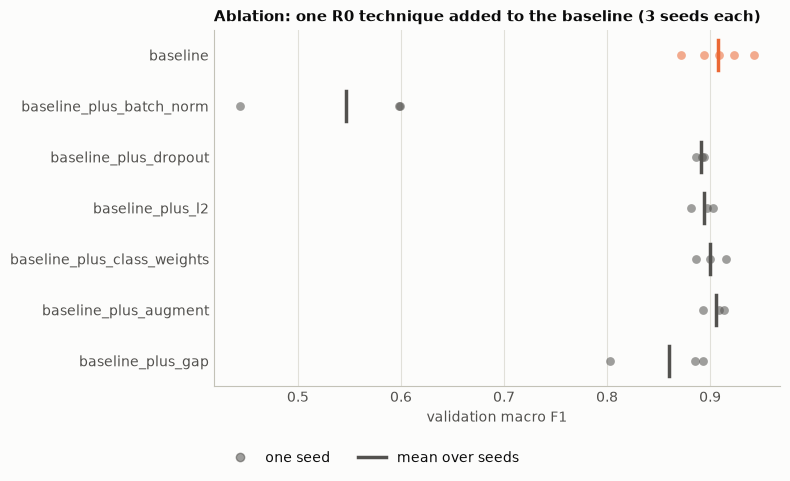

In [20]:
ablation = ["baseline", "baseline_plus_batch_norm", "baseline_plus_dropout", "baseline_plus_l2",
            "baseline_plus_class_weights", "baseline_plus_augment", "baseline_plus_gap"]
views.plot_seed_scores(results, ablation, "Ablation: one R0 technique added to the baseline (3 seeds each)")

**Ablation (3 seeds each, so these are not candidates for selection)**

- **No single technique improves the baseline.** Dropout, L2, class weights and medium augmentation stay within one std of 0.908. Augmentation moves the best epoch later (less overfitting) but not the score.
- **Global average pooling** alone drops to 0.860 with 28 thousand parameters. Two convolution layers are too shallow to work without the big dense layer.
- **Batch normalization** alone collapses all 3 seeds: the same momentum 0.99 lag.
- So the gain of the optimized model comes from the **combination**: a deeper network that can afford global average pooling, plus batch normalization that is allowed to settle.

## 8. Model selection

The rule was written before Section 5 ran (`experiments/DECISION.md`):

1. Only configurations with 5 seeds whose worst seed reaches validation macro F1 0.85 are eligible.
2. The highest mean wins. A configuration within one std of the top mean is a tie, and the tie goes to the lower std.

In [21]:
summary_all = selection.config_summary(results)
eligible = selection.eligible(summary_all)
chosen = selection.select_config(summary_all)
print("Selected:", chosen["cfg_name"])
eligible.set_index("cfg_name")[["seeds", "f1_mean", "f1_std", "f1_min", "rainy_f1_mean", "epochs_mean"]].round(4)

Selected: r0_patience30_min20


,seeds,f1_mean,f1_std,f1_min,rainy_f1_mean,epochs_mean
cfg_name,,,,,,
r0_bn_momentum_0.9,5.0,0.9403,0.0045,0.9340,0.9743,48.8
r0_patience30_min20,5.0,0.9368,0.0041,0.9342,0.9651,73.4
r0_bn_momentum_0.8,5.0,0.9364,0.0181,0.9099,0.9707,54.6
baseline,5.0,0.9080,0.0271,0.8716,0.9626,22.6


- Momentum 0.9 has the top mean (0.9403). The later stopping rule (0.9368) and momentum 0.8 (0.9364) are within one std of it, so the three are tied, and **r0_patience30_min20** wins the tie with the lowest std (0.0041).
- The three are equivalent on validation. Momentum 0.9 is the cheaper alternative and is kept as the fallback. The rule was fixed in advance, so it was applied as written.
- The baseline is 0.032 below the top, more than one std, with 27 times more parameters.

## 9. Baseline against the selected model on validation

Four metrics plus the confusion matrix, computed from the saved validation predictions of every seed (`val_predictions.csv`):

- **Accuracy**: share of images classified correctly.
- **Macro precision, recall and F1**: computed per class, then averaged with equal weight per class, so the small rainy class counts as much as sunrise. F1 is the harmonic mean of precision and recall.
- **Log loss**: how confident the model is in the right class (lower is better).
- **ROC AUC (macro)**: how well the predicted probabilities rank each class above the others, independent of the threshold.

In [22]:
views.seed_metrics_table(results, "baseline")

,accuracy,loss,macro_precision,macro_recall,macro_f1,roc_auc_macro
s3_baseline_seed11,0.875,0.463,0.906,0.853,0.872,0.969
s3_baseline_seed22,0.889,0.415,0.896,0.902,0.894,0.977
s3_baseline_seed33,0.903,0.376,0.912,0.906,0.909,0.979
s3_baseline_seed44,0.938,0.356,0.943,0.942,0.943,0.980
s3_baseline_seed55,0.917,0.364,0.922,0.923,0.923,0.978
mean,0.904,0.395,0.916,0.905,0.908,0.976
std,0.024,0.045,0.018,0.033,0.027,0.004


In [23]:
views.seed_metrics_table(results, views.SELECTED_NAME)

,accuracy,loss,macro_precision,macro_recall,macro_f1,roc_auc_macro
s5_r0_patience30_min20_seed11,0.938,0.145,0.935,0.941,0.937,0.995
s5_r0_patience30_min20_seed22,0.931,0.202,0.930,0.942,0.934,0.991
s5_r0_patience30_min20_seed33,0.931,0.167,0.930,0.942,0.934,0.995
s5_r0_patience30_min20_seed44,0.931,0.199,0.938,0.936,0.935,0.992
s5_r0_patience30_min20_seed55,0.944,0.138,0.942,0.948,0.944,0.996
mean,0.935,0.170,0.935,0.942,0.937,0.994
std,0.006,0.030,0.005,0.004,0.004,0.002


- The selected model is better on every metric on average and much more stable: macro F1 0.937 +- 0.004 against 0.908 +- 0.027, and the log loss is less than half (0.17 against 0.40), so its probabilities are also better calibrated.

Per-class precision and recall (mean over the 5 seeds):

In [24]:
views.per_class_table(results, ["baseline", views.SELECTED_NAME])

precision                       recall                           f1                    
config   baseline r0_patience30_min20 baseline r0_patience30_min20 baseline r0_patience30_min20
class                                                                                          
cloudy      0.884               0.973    0.883               0.883    0.880               0.926
rainy       0.990               0.961    0.940               0.970    0.963               0.965
shiny       0.823               0.831    0.830               0.952    0.822               0.887
sunrise     0.967               0.976    0.967               0.963    0.967               0.969

- **Precision** answers "when the model says this class, how often is it right?". **Recall** answers "of the images of this class, how many does it find?".
- The biggest gain is **shiny recall** (0.83 to 0.95) and **cloudy precision** (0.88 to 0.97): the selected model stops calling clear skies cloudy (21 shiny images called cloudy by the baseline over 5 seeds, 2 by the selected model).
- **Rainy** stays high for both models (recall 0.94 and 0.97). For a rain detection use case, rainy recall is the key number: a missed rainy image is the costly error.

Confusion matrices, summed over the 5 seeds (720 predictions each). Rows are the true class, columns the prediction, each cell shows the count and the share of its row:

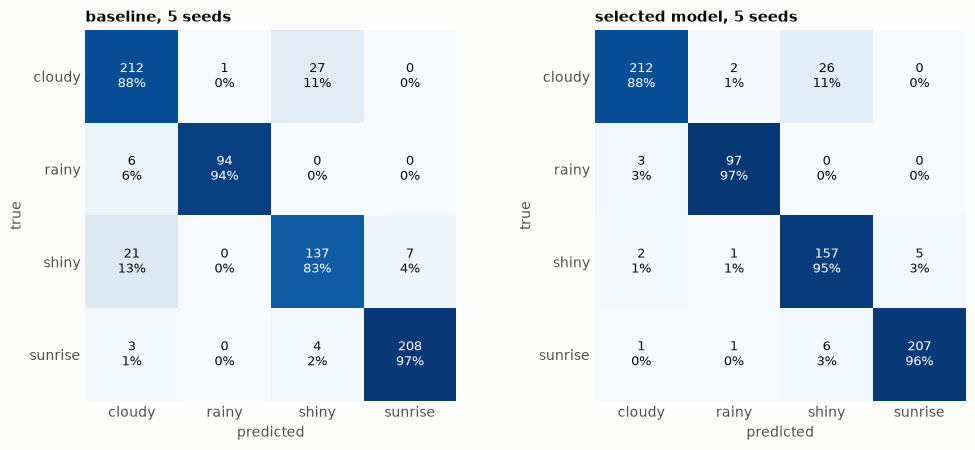

In [25]:
views.plot_confusions({"baseline, 5 seeds": views.pooled_confusion(results, "baseline"),
                       "selected model, 5 seeds": views.pooled_confusion(results, views.SELECTED_NAME)})

- The remaining weak spot is **cloudy predicted as shiny** (26 of 240 cloudy predictions, 11%), the same as the baseline (27). The optimizations fixed the opposite direction but not this one. Rainy is never confused with shiny or sunrise, and only 3 of 100 rainy predictions went to cloudy.

## 10. Where the selected model fails

The misclassified validation images of the best seed (seed 55), most confident mistakes first:

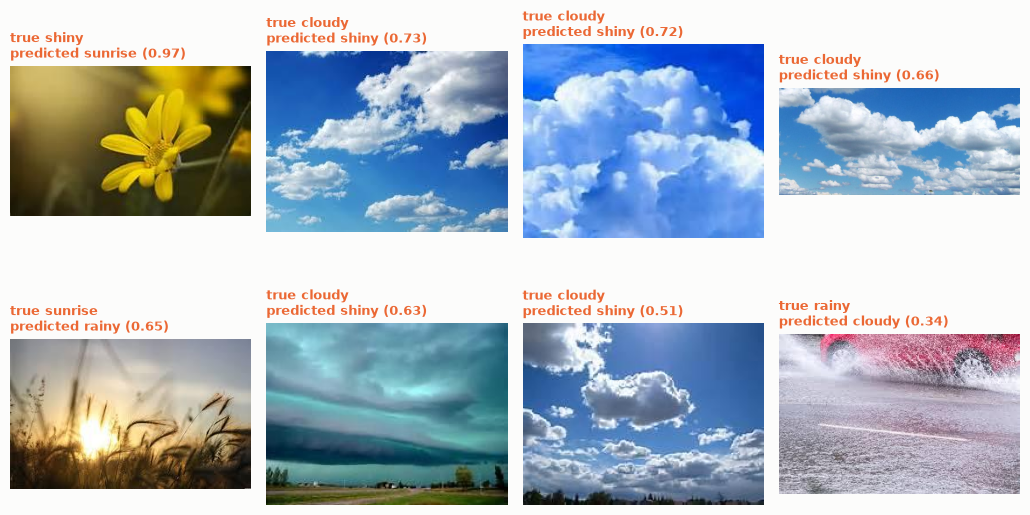

In [26]:
best_run = "s5_r0_patience30_min20_seed55"
wrong = views.misclassified(best_run)
views.plot_gallery(wrong)

- Five of the eight mistakes are **white cumulus clouds on a blue sky** labelled cloudy and predicted shiny. A person could give either label, so part of the cloudy and shiny confusion is label ambiguity in the dataset (also seen in the Section 1 label review), not only a model limit.
- A close-up of a yellow flower labelled shiny is called sunrise: warm golden colors dominate the image.
- A backlit wheat field at sunset is called rainy, and a car splashing water on a wet road (rainy) is called cloudy with low confidence (0.34). The API marks predictions below 0.6 confidence as uncertain, which would flag that one.

## 11. Final model and the locked test set (Section 7)

The final model is produced by the Section 7 job on Kaggle (`src/final_model.py`):

1. Train the selected configuration with the 5 seeds and pick the seed with the best validation macro F1 (validation only).
2. Save `models/weather_cnn.h5` and export `models/weather_cnn.onnx`.
3. Check that ONNX and Keras give the same probabilities on all 144 validation images before the test set is loaded.
4. Evaluate the 134 test images **once** and write `models/metrics.json` with a `validation` and a `test` section, bootstrap 95% confidence intervals and the parity results.

The cells below only read saved records. They use `models/metrics.json` (the served model) when it has a test section, and otherwise `experiments/final_model/metrics.json`, the copy of the Section 7 record that a promoted retrain never replaces. The first cell prints which source is shown. If neither exists they print how to produce it.

In [27]:
record, source = views.load_final_record()
if record is None:
    print(views.final_model_missing())
else:
    print(views.record_source(source))
    display(views.final_description(record))

Source: models/metrics.json, the record of the model the API serves now.


version          weather_cnn_s7_r0_patience30_min20_seed55
run_id                       s7_r0_patience30_min20_seed55
seed                                                    55
created_at                       2026-11-25T12:19:14+00:00
export_method                                   from_keras
config_hash                                       d2450b51
train images                                           719
valid images                                           144
test images                                            134
Name: final model, dtype: object

The Section 7 job trained the selected configuration again with the same 5 seeds as Section 5 (same configuration hash, same TensorFlow 2.21.0, same T4 GPU). GPU training is not bit-for-bit reproducible, so the two sets of runs differ:

In [28]:
if record is not None:
    display(views.rerun_table(views.load_all_results()))

,section 5 val macro F1,section 7 val macro F1,section 7 minus section 5
11,0.9368,0.9526,0.0157
22,0.9342,0.9438,0.0096
33,0.9342,0.9406,0.0065
44,0.9351,0.9467,0.0116
55,0.9440,0.9619,0.0179
mean,0.9368,0.9491,0.0123
std,0.0041,0.0084,0.0046


- All 5 Section 7 runs scored higher on validation than their Section 5 twins (mean +0.012, larger than the Section 5 std of 0.004). The epoch-1 validation losses agree to about 3 decimals, then the runs drift apart. If each pair were a coin flip, all 5 going the same way would happen 1 time in 32, so this may be chance, but it is logged as an open question.
- It does not affect the choice of configuration, which was fixed in Section 5 before this job ran. Over all 10 runs the configuration averages 0.943 +- 0.009.

In [29]:
if record is not None:
    display(views.final_overview(record))

,validation,test (95% CI),test minus validation
accuracy,0.965,0.903 (0.851 to 0.948),-0.062
loss,0.144,0.303,+0.159
macro_precision,0.966,0.900,-0.066
macro_recall,0.959,0.907,-0.052
macro_f1,0.962,0.900 (0.845 to 0.947),-0.062
roc_auc_macro,0.998,0.982,-0.016


- **Validation is optimistic.** Seed 55 was picked because it had the best validation macro F1 of the 5 seeds (0.962). The 5 seeds averaged 0.949 +- 0.008, so the pick alone adds about 0.013. The validation number of the shipped model is the best of 5 draws, not a fair estimate of new-image performance. The test number is the one to quote.
- **Test macro F1 is 0.900** (95% CI 0.845 to 0.947), accuracy 0.903. Test minus validation is -0.062; against the 5-seed validation mean it is -0.049. The interval still contains the 10-run validation mean of the configuration (0.943).
- The drop is a little larger than the 0.05 named in the hypothesis before the run (S7-E1 in `experiments/EXPERIMENT_LOG.md`), so it was investigated from the saved test predictions, without evaluating anything again: the errors follow the same cloudy and shiny pattern as on validation (below), and the wrong predictions are much less confident (median 0.76) than the right ones (median 0.996).
- The **95% confidence interval** comes from resampling the 134 test images 2000 times. With 29 to 40 test images per class it is about 0.10 wide, so small differences inside it mean nothing.

In [30]:
if record is not None:
    display(views.final_per_class(record))

,val precision,val recall,val f1,test precision,test recall,test f1 (95% CI),test images
cloudy,0.96,1.0,0.979592,0.78125,0.862069,0.820 (0.696 to 0.912),29
rainy,0.95,0.95,0.95,0.875,0.965517,0.918 (0.833 to 0.983),29
shiny,1.0,0.909091,0.952381,0.969697,0.8,0.877 (0.790 to 0.950),40
sunrise,0.954545,0.976744,0.965517,0.972973,1.0,0.986 (0.953 to 1.000),36


- **Rainy**, the class this use case cares about most: test recall 0.966 (28 of 29 rainy images found), F1 0.918 (0.833 to 0.983).
- **Sunrise** is almost perfect (F1 0.986).
- **Shiny** recall drops to 0.80: 6 of the 40 shiny test images are called cloudy and 2 are called rainy. The 6 shiny images called cloudy also lower cloudy precision to 0.78, so cloudy F1 is 0.820. This is the same cloudy and shiny ambiguity as in the validation gallery of section 10, and the test set has more shiny images (40) than validation (33).

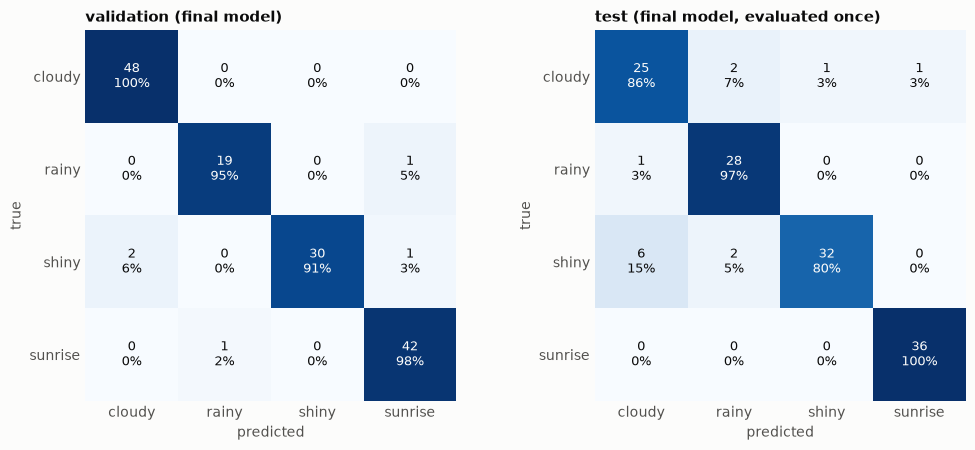

In [31]:
if record is not None:
    display(views.final_confusions(record))

## 12. Prediction functions

The API calls `src.prediction`: it preprocesses the image with the functions of Section 2, runs the ONNX model with ONNX Runtime, and returns the label, the confidence, the probability of every class and an `uncertain` flag (confidence below 0.6). The demo uses validation images, some predicted right and some wrong by the seed 55 run, so the test set stays untouched.

In [32]:
demo = views.demo_rows(best_run)
if views.FINAL_ONNX_PATH.exists():
    display(views.predict_examples(demo))
else:
    print(f"{views.FINAL_ONNX_PATH} is not installed yet, the saved validation predictions of {best_run} are shown instead.")
    display(demo[["path", "true", "predicted", "confidence"]])

,label,confidence,uncertain,true
file,,,,
cloudy111_jpg.rf.55c538356941041de1f01b963acd112b.jpg,cloudy,0.8905,False,cloudy
rain105_jpg.rf.15b3a51ee76c6de91126452bcbee683e.jpg,rainy,0.9904,False,rainy
shine10_jpg.rf.77241d6512984fc21f942d8b8b5154c2.jpg,shiny,0.7800,False,shiny
sunrise115_jpg.rf.4cd742f5e5e62d0168f275c8826e2750.jpg,sunrise,0.9927,False,sunrise
shine252_jpg.rf.dfd063e8e9d817ffe6fb8ce583e325ed.jpg,sunrise,0.9776,False,shiny
cloudy113_jpg.rf.6bc39152f3263f2562c1edbbcd930822.jpg,cloudy,0.5926,True,cloudy
cloudy225_jpg.rf.7ac1d3abaf11c3c6b5a576d2557e5923.jpg,cloudy,0.5666,True,cloudy
cloudy109_jpg.rf.bb4e129312c95ed0de20a21acae282e2.jpg,cloudy,0.7194,False,cloudy


## 13. ONNX export and parity

- `src/onnx_export.py` converts the Keras model with `tf2onnx.convert.from_keras`. If that fails, it exports a TensorFlow SavedModel and converts it with `python -m tf2onnx.convert --saved-model`.
- The deployed API uses only ONNX Runtime on CPU, so the exported file has to give the same answers as the trained Keras model. Parity is measured on CPU for both: Section 5 showed that GPU kernels alone move the probabilities by about 1.5e-4, which would hide the export itself.
- Pass condition: largest absolute probability difference below 1e-4 and the same predicted class for every image.

In [33]:
if record is not None:
    display(views.parity_table(record))
else:
    print(views.final_model_missing())

,n_images,max_abs_diff,same_class_share,tolerance,passed
validation,144,0.000001,1.0,0.0001,True
test,134,0.000001,1.0,0.0001,True


## 14. Retraining

Retraining is implemented in `src/retrain.py` and started from the trainer API or the UI:

- Users upload labelled images, which are saved in `data/uploads/<class>/` and recorded in SQLite.
- When enough new uploads exist (40 by default) a retraining job starts automatically, or a user starts it by hand.
- The job loads **our own saved model** (`models/weather_cnn.h5`, never pretrained weights), fine-tunes it at a low learning rate (1e-4) on the training images plus the uploads with the same preprocessing and augmentation, and exports a candidate ONNX file.
- The candidate replaces the served model only if its validation macro F1 is at least as good as the current model. The old files are archived in `models/archive/`.

## 15. Conclusions

- A custom CNN trained from scratch reaches **0.937 +- 0.004 validation macro F1** over 5 seeds, against 0.908 +- 0.027 for a plain CNN, with 27 times fewer parameters. Rainy F1 is 0.965 on average.
- The optimized model only works when batch normalization is allowed to settle: with 23 training steps per epoch, momentum 0.99 lags for about 15 epochs. A lower momentum or a stopping rule that waits out the lag both fix it. A smaller learning rate, a warmup or lighter augmentation do not.
- No single technique improves the plain CNN on its own. The gain comes from the combination of depth, global average pooling and batch normalization.
- The main remaining error is cloudy against shiny, which is partly label ambiguity in the dataset.
- On the locked test set, evaluated once after every decision was made on validation, the final model (seed 55) reaches **macro F1 0.900** (95% CI 0.845 to 0.947), accuracy 0.903 and rainy recall 0.966. Its validation macro F1 (0.962) is optimistic because the seed was the best of 5 picked on validation.